Цель:
настроить систему по поиску аномалий в банковских транзакциях.
Мало того, что аномальных значений в данных меньше одного процента, так еще и переменные анонимизированные и представляют собой первые 28 главных компонент, полученных после PCA преобразования оригинальных данных (о которых мы ничего не знаем).
Смогут ли бравые unsupervised методы справиться с такой задачей? Можно ли работать в таких условиях? Кто подставил кролика Роджера? Ответы на некоторые их этих вопросов вы узнаете после выполнения задания :)


Описание/Пошаговая инструкция выполнения домашнего задания:
Скачайте датасет с https://www.kaggle.com/mlg-ulb/creditcardfraud#creditcard.csv
Проведите небольшой EDA (гистограммы и описательные статистики - обязательно).
Воспользуйтесь процентом аномалий, подсчитанным по переменной Class, как "экспертной оценкой" загрязненности нашего датасета.
Попробуйте построить различные модели и алгоритмы, разобранные на занятии, используя полученную экспертную оценку для настройки параметров.
Воспользуйтесь стандартными методами оценки качества бинарной классификации (особенно хорошо подойдёт classification report и confusion matrix), и, используя предсказания моделей и переменную Class, проверьте, действительно ли модели справляются со своей задачей и насколько хорошо они это делают.
При помощи tSNE и/или UMAP, постройте сжатое представление исходных данных и проверьте, действительно ли аномалии лежат достаточно далеко от основной массы точек.

Критерии оценки:
Базовый EDA - 2 балла.
Построены различные алгоритмы по поиску аномалий (основанные на расстояниях, плотностях и используя модели) - 5 баллов.
Проверка качества и отображение на сжатое пространство - 3 балла

In [2]:
# =====================
# 1. CSV load and setup configs
# =====================

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configs
RANDOM_STATE = 555
pd.set_option('display.max_columns', None)

# Directories
input_dir = 'csv_input'
output_dir = 'csv_output'
os.makedirs(output_dir, exist_ok=True)

file_path = os.path.join(input_dir, 'creditcard.csv')

# Read only column names
all_cols = pd.read_csv(file_path, nrows=0).columns.tolist()
print('All columns:')
print(all_cols)

# Configure list of columns to exclude
exclude_cols = []

# Define columns to keep
use_cols = [col for col in all_cols if col not in exclude_cols]

# Load dataset without excluded columns
df_raw = pd.read_csv(file_path, usecols=use_cols)

print(f'\nDataset loaded: {file_path} \nwithout these cols: {exclude_cols}')
print('Shape:', df_raw.shape)
display(df_raw.head())


All columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset loaded: csv_input\creditcard.csv 
without these cols: []
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df_raw.describe()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


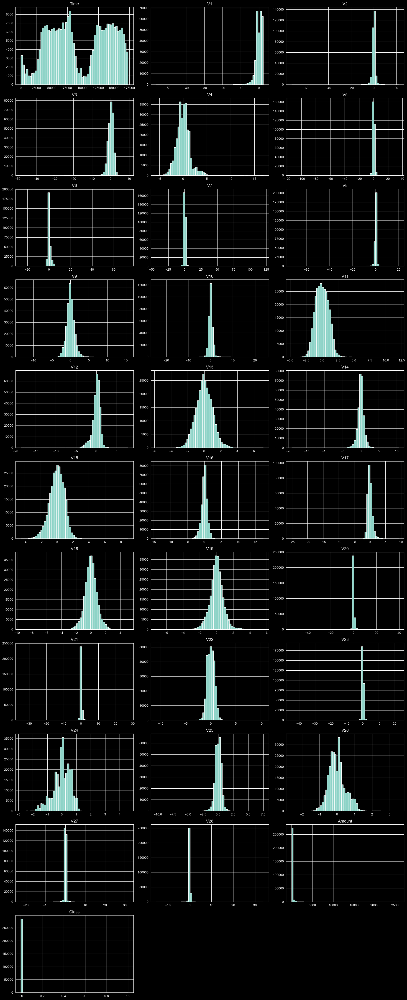

In [4]:
fig, axes = plt.subplots(
    nrows=(len(df_raw.columns) + 2) // 3,  # 3 columns per row
    ncols=3,
    figsize=(18, 44)
)

# Flatten and plot
for ax, column in zip(axes.flat, df_raw.columns):
    df_raw[column].hist(ax=ax, bins=60)
    ax.set_title(column, fontsize=13)

# Remove empty subplots
for ax in axes.flat[len(df_raw.columns):]:
    ax.axis('off')

plt.tight_layout()
plt.show()


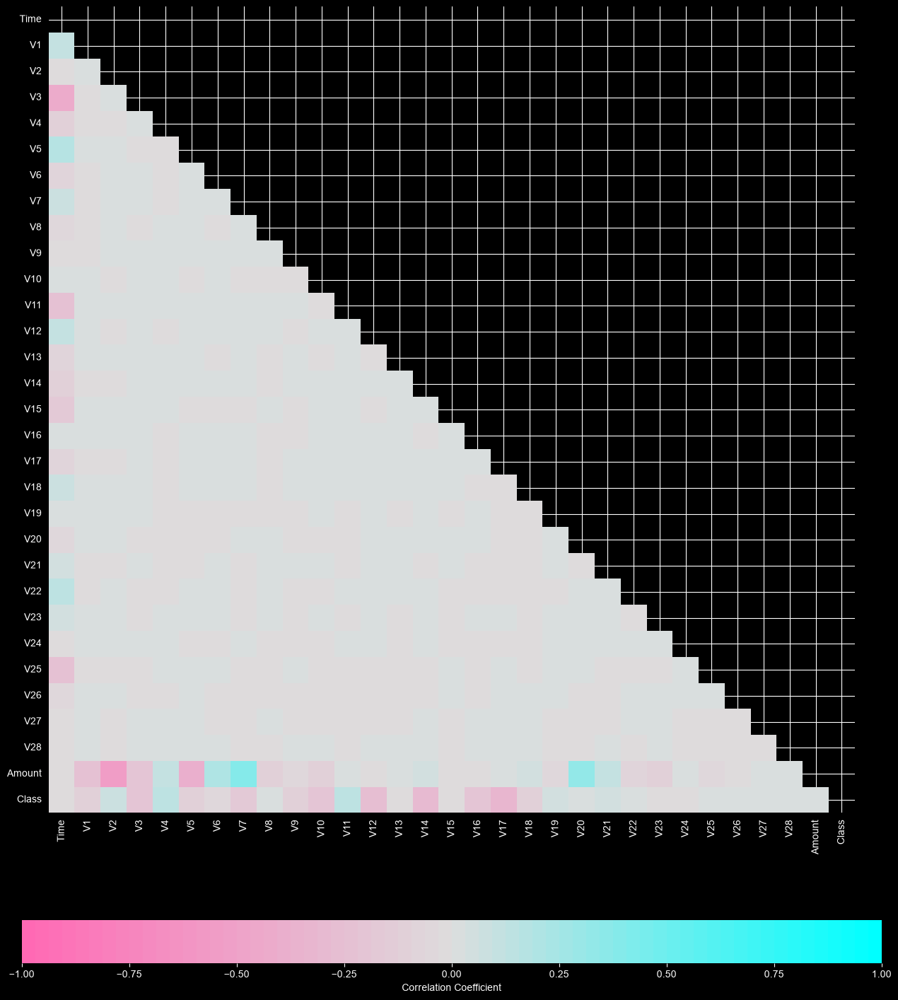

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

n_features = df_raw.shape[1]

# Compact size
fig_size = min(16, max(6, n_features * 0.5))

plt.figure(figsize=(fig_size, fig_size))

colors = ['#FF69B4', '#DDDDDD', '#00FFFF']
cmap = LinearSegmentedColormap.from_list('pink_cyan', colors, N=64)

corr_matrix = df_raw.corr()
lower = corr_matrix.where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))

sns.heatmap(lower, annot=False, cbar=True, center=0, cmap=cmap, square=True,
            vmin=-1, vmax=1,
            cbar_kws={'label': 'Correlation Coefficient',
                      'orientation': 'horizontal',  # Horizontal colorbar
                      'shrink': 0.8,
                      'pad': 0.1,
                      'ticks': [-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1]})

plt.tight_layout()
plt.show()


In [6]:
high_corr = [
    column for column in lower.columns if any((lower[column] > 0.5)|(lower[column] < -0.5))
]
high_corr

['V2']

In [7]:
def outlier_std(data, col, threshold=3):
    mean = data[col].mean()
    std = data[col].std()
    up_bound = mean + threshold * std
    low_bound = mean - threshold * std
    anomalies = pd.concat([data[col]>up_bound, data[col]<low_bound], axis=1).any(axis = 1)
    return anomalies, up_bound, low_bound

In [8]:
def get_column_outliers(data, columns=None, function=outlier_std, threshold=3):
    columns = data.columns if columns is None else columns

    masks = {}
    statistics = []

    for column in columns:
        mask, upper, lower = function(data, column, threshold=threshold)
        masks[column] = mask
        count = int(mask.sum())

        statistics.append({
            'column': column,
            'upper_bound': upper,
            'lower_bound': lower,
            'anomalies_count': count,
            'anomalies_percentage': 100 * mask.mean(),
        })

    comparison_table = pd.DataFrame(statistics).set_index('column').sort_values(
            'anomalies_percentage',
            ascending=False,
        )

    outliers = pd.DataFrame(masks, index=data.index).any(axis=1).rename('is_outlier')

    return comparison_table, outliers


def anomalies_report(outliers):
    print('Number of outliers: {}'.format(sum(outliers)))
    print('Percentage of outliers:  {:.2f}%'.format(100 * sum(outliers) / len(outliers)))

data_features = df_raw.iloc[:, :-1]

comparison_table, std_outliers = get_column_outliers(data_features)
anomalies_report(std_outliers)

print('\nTop 10 columns 3-sigma outlier share:')
display(comparison_table.head(10))


Number of outliers: 37816
Percentage of outliers:  13.28%

Top 10 columns 3-sigma outlier share:


,upper_bound,lower_bound,anomalies_count,anomalies_percentage
column,,,,
V27,1.210897,-1.210897,4771,1.675170
V6,3.996813,-3.996813,4652,1.633387
V20,2.312775,-2.312775,4645,1.630929
V2,4.953926,-4.953926,4318,1.516114
V8,3.583059,-3.583059,4221,1.482056
Amount,838.709947,-662.010708,4076,1.431145
V21,2.203572,-2.203572,4064,1.426931
V1,5.876087,-5.876087,3701,1.299476
V10,3.266549,-3.266549,3488,1.224689


In [9]:
class_counts = df_raw['Class'].value_counts()
print(class_counts)
print('Anomaly percent by expert: {:.4%}'.format(df_raw['Class'].mean()))


Class
0    284315
1       492
Name: count, dtype: int64
Anomaly percent by expert: 0.1727%


In [10]:
from datetime import datetime
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

#--------------------
# Config
#--------------------

results_path = os.path.join(output_dir, 'model_results.csv')

def save_results(results_dict, filepath):
    new_data = pd.DataFrame([results_dict])
    if os.path.exists(filepath):
        existing_data = pd.read_csv(filepath)
        combined_data = pd.concat([existing_data, new_data], ignore_index=True)
        combined_data.to_csv(filepath, index=False)
    else:
        new_data.to_csv(filepath, index=False)

def load_results(filepath):
    if os.path.exists(filepath):
        return pd.read_csv(filepath)
    return pd.DataFrame()

if os.path.exists(results_path):
    os.remove(results_path)
    print('Cleared previous results')

#--------------------
# 2. Duplicates and nulls
#--------------------

print('Raw shape:', df_raw.shape)

null_counts = df_raw.isnull().sum().sum()
print('Total nulls:', null_counts)

dup_count = df_raw.duplicated().sum()
print('Total duplicates found:', dup_count)

df_clean = df_raw.drop_duplicates().dropna().reset_index(drop=True)

print('Shape after cleaning:', df_clean.shape)


Cleared previous results
Raw shape: (284807, 31)
Total nulls: 0
Total duplicates found: 1081
Shape after cleaning: (283726, 31)


In [11]:
#--------------------
# 3. EDA section
#--------------------

display(df_clean.describe())

for col in ['Time', 'Amount']:
    fig = px.histogram(df_clean, x=col, title='Distribution of:  ' + col,
                       color_discrete_sequence=['#636EFA'], marginal='box')
    fig.show()

class_counts = df_clean['Class'].value_counts().reset_index()
class_counts.columns = ['Class', 'Count']
class_counts['Class'] = class_counts['Class'].astype(str)

fig = px.bar(class_counts, x='Class', y='Count', text='Count',
             title='Distribution of Target (Class)',
             color='Class', color_discrete_map={'0': 'blue', '1': 'red'})
fig.update_traces(textposition='outside')
fig.show()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,-0.001441,0.000202,-0.000715,0.000603,0.000252,0.001043,0.001162,0.000170,0.001515,-0.000264,0.000187,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,1.076407,1.018720,0.994674,0.995430,0.952215,0.914894,0.873696,0.842507,0.837378,0.813379,0.769984,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,-24.588262,-4.797473,-18.683715,-5.791881,-19.214325,-4.498945,-14.129855,-25.162799,-9.498746,-7.213527,-54.497720,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,-0.535578,-0.761649,-0.406198,-0.647862,-0.425732,-0.581452,-0.466860,-0.483928,-0.498014,-0.456289,-0.211469,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,-0.093237,-0.032306,0.139072,-0.012927,0.050209,0.049299,0.067119,-0.065867,-0.002142,0.003367,-0.062353,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,0.453619,0.739579,0.616976,0.663178,0.492336,0.650104,0.523512,0.398972,0.501956,0.458508,0.133207,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,23.745136,12.018913,7.848392,7.126883,10.526766,8.877742,17.315112,9.253526,5.041069,5.591971,39.420904,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


In [12]:
#--------------------
# 4. Expert Estimation, Train Test Split, Scaling
#--------------------

anomaly_rate = df_clean['Class'].mean()
print('Expert anomaly rate:', anomaly_rate)

X = df_clean.drop(columns=['Class'])
y = df_clean['Class']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)

# Scaler to equalize Time, Amount with V1-V28
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# DF size for SVM, DBSCAN
X_train_sample = X_train_scaled.sample(n=15000, random_state=RANDOM_STATE)
y_train_sample = y_train.loc[X_train_sample.index]

print('\nSVM DBSCAN limited size:')
print('X_train_sample:', X_train_sample.shape)
print('y_train_sample:', y_train_sample.shape)


Expert anomaly rate: 0.001667101358352777
Train shape: (226980, 30)
Test shape: (56746, 30)

SVM DBSCAN limited size:
X_train_sample: (15000, 30)
y_train_sample: (15000,)


In [13]:
#--------------------
# 5. Anomaly detection models from lecture
#--------------------

def evaluate_and_save(model_name, y_true, y_pred, hyperparams, dataset_type):
    # y_pred already encoded: 1 = anomaly, 0 = normal
    y_pred = np.asarray(y_pred).astype(int)
    y_true = np.asarray(y_true)

    print('\nClass report for ' + model_name + ' on ' + dataset_type)
    print(classification_report(y_true, y_pred, target_names=['Normal', 'Anomaly'], zero_division=0))

    cm = confusion_matrix(y_true, y_pred)

    cyan_pink_scale = [
    [0.0, '#00FFFF'],  # Cyan
    [0.5, '#FFFFFF'],  # White (middle)
    [1.0, '#FF69B4'],  # Pink
]

    fig = px.imshow(cm, text_auto=True, title='Confusion matrix: ' + model_name + ' ' + dataset_type,
                    labels=dict(x='Predicted', y='Actual'),
                    x=['Normal', 'Anomaly'],
                    y=['Normal', 'Anomaly'],
                    color_continuous_scale=cyan_pink_scale)
    fig.show()

    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    results = {
        'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'model': model_name + '_' + dataset_type,
        'hyperparameters': str(hyperparams),
        'recall': report['1']['recall'],
        'precision': report['1']['precision'],
        'f1': report['1']['f1-score'],
        'predicted_anomalies': int(y_pred.sum()),
        'actual_anomalies': int(y_true.sum())
    }
    save_results(results, results_path)

In [14]:
#--------------------
# 5. Anomaly Detection Models
#--------------------

# 1. 3-Sigma
# how many features are beyond 3 sigma distance from the column mean value.
# the logged variant calibrated, so the flagged anomalies match the expert estimate.
sigma_threshold = 3

train_mean = X_train.mean()
train_std = X_train.std()
train_violations = ((X_train - train_mean).abs() / train_std > sigma_threshold).sum(axis=1)
test_violations = ((X_test - train_mean).abs() / train_std > sigma_threshold).sum(axis=1)

anomaly_percent = train_violations.gt(0).mean()
print('Beyond 3-sigma {} values {:.2%} of train rows'.format(
    sigma_threshold, anomaly_percent))

# Calibrate
n_flag = int(np.ceil(anomaly_rate * len(train_violations)))
sigma_cutoff = train_violations.sort_values(ascending=False).iloc[n_flag - 1]
print('Calibrate 3-sigma: flag rows if at least {} violations out of {} features'.format(
    sigma_cutoff, X_train.shape[1]))
print('Calibrated 3-sigma flagged anomalies: train {:.2%}, test {:.2%}'.format(
    train_violations.ge(sigma_cutoff).mean(), test_violations.ge(sigma_cutoff).mean()))

std_params = {'threshold': sigma_threshold, 'min_violations': int(sigma_cutoff)}
train_pred_std = train_violations.ge(sigma_cutoff).astype(int)
test_pred_std = test_violations.ge(sigma_cutoff).astype(int)
evaluate_and_save('3Sigma', y_train, train_pred_std, std_params, 'TRAIN')
evaluate_and_save('3Sigma', y_test, test_pred_std, std_params, 'TEST')


Beyond 3-sigma 3 values 13.53% of train rows
Calibrate 3-sigma: flag rows if at least 11 violations out of 30 features
Calibrated 3-sigma flagged anomalies: train 0.20%, test 0.22%

Class report for 3Sigma on TRAIN
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    226602
     Anomaly       0.27      0.33      0.29       378

    accuracy                           1.00    226980
   macro avg       0.63      0.66      0.65    226980
weighted avg       1.00      1.00      1.00    226980




Class report for 3Sigma on TEST
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56651
     Anomaly       0.23      0.31      0.26        95

    accuracy                           1.00     56746
   macro avg       0.62      0.65      0.63     56746
weighted avg       1.00      1.00      1.00     56746



In [15]:
# 2. Isolation Forest
iso_params = {'n_estimators': 100, 'contamination': anomaly_rate, 'random_state': RANDOM_STATE}
iso_model = IsolationForest(**iso_params)
iso_model.fit(X_train_scaled)
train_pred_iso = (iso_model.predict(X_train_scaled) == -1).astype(int)
test_pred_iso = (iso_model.predict(X_test_scaled) == -1).astype(int)
evaluate_and_save('IsolationForest', y_train, train_pred_iso, iso_params, 'TRAIN')
evaluate_and_save('IsolationForest', y_test, test_pred_iso, iso_params, 'TEST')



Class report for IsolationForest on TRAIN
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    226602
     Anomaly       0.23      0.23      0.23       378

    accuracy                           1.00    226980
   macro avg       0.61      0.61      0.61    226980
weighted avg       1.00      1.00      1.00    226980




Class report for IsolationForest on TEST
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56651
     Anomaly       0.15      0.17      0.16        95

    accuracy                           1.00     56746
   macro avg       0.58      0.58      0.58     56746
weighted avg       1.00      1.00      1.00     56746



In [16]:
# 3. One-Class SVM (limited df size)
svm_params = {'nu': anomaly_rate, 'kernel': 'rbf', 'gamma': 'scale'}
svm_model = OneClassSVM(**svm_params)
svm_model.fit(X_train_sample)
train_pred_svm = (svm_model.predict(X_train_scaled) == -1).astype(int)
test_pred_svm = (svm_model.predict(X_test_scaled) == -1).astype(int)
evaluate_and_save('OneClassSVM', y_train, train_pred_svm, svm_params, 'TRAIN')
evaluate_and_save('OneClassSVM', y_test, test_pred_svm, svm_params, 'TEST')



Class report for OneClassSVM on TRAIN
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98    226602
     Anomaly       0.04      0.82      0.08       378

    accuracy                           0.97    226980
   macro avg       0.52      0.89      0.53    226980
weighted avg       1.00      0.97      0.98    226980




Class report for OneClassSVM on TEST
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98     56651
     Anomaly       0.04      0.86      0.08        95

    accuracy                           0.97     56746
   macro avg       0.52      0.91      0.53     56746
weighted avg       1.00      0.97      0.98     56746



In [17]:
# 4. Local Outlier Factor (LOF)
lof_params = {'n_neighbors': 20, 'contamination': anomaly_rate, 'novelty': True}
lof_model = LocalOutlierFactor(**lof_params)
lof_model.fit(X_train_scaled)
train_pred_lof = (lof_model.predict(X_train_scaled) == -1).astype(int)
test_pred_lof = (lof_model.predict(X_test_scaled) == -1).astype(int)
evaluate_and_save('LOF', y_train, train_pred_lof, lof_params, 'TRAIN')
evaluate_and_save('LOF', y_test, test_pred_lof, lof_params, 'TEST')



Class report for LOF on TRAIN
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    226602
     Anomaly       0.00      0.00      0.00       378

    accuracy                           1.00    226980
   macro avg       0.50      0.50      0.50    226980
weighted avg       1.00      1.00      1.00    226980




Class report for LOF on TEST
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56651
     Anomaly       0.00      0.00      0.00        95

    accuracy                           1.00     56746
   macro avg       0.50      0.50      0.50     56746
weighted avg       1.00      1.00      1.00     56746



In [18]:
# 5. DBSCAN (limited df size, anomalies labeled -1)
'''
so,eps is calibrated with the expert marks: the distance to min_samples-th
nearest neighbor checked for every point of the sample,
eps radius set to quantile (1 - contamination),
we expect, anomaly_rate of points should be in sparse space and becomes noise
'''
dbscan_min_samples = 5

knn = NearestNeighbors(n_neighbors=dbscan_min_samples)
knn.fit(X_train_sample)
k_dist, _ = knn.kneighbors(X_train_sample)
k_dist_sorted = np.sort(k_dist[:, -1])

fig = px.line(x=np.arange(len(k_dist_sorted)), y=k_dist_sorted,
              title='k-distance graph (distance to {}-th nearest neighbor, sorted)'.format(
                  dbscan_min_samples),
              labels={'x': 'points sorted by k-distance', 'y': 'k-distance'})
fig.show()

eps = float(np.quantile(k_dist[:, -1], 1 - anomaly_rate))
dbscan_params = {'eps': eps, 'min_samples': dbscan_min_samples, 'n_jobs': -1}
print('Calibrated eps:', eps)

dbscan_model = DBSCAN(**dbscan_params)
train_pred_dbscan = (dbscan_model.fit_predict(X_train_sample) == -1).astype(int)
print('Noise percent on the fit sample: {:.2%}'.format(train_pred_dbscan.mean()))

# Test point is anomaly if it is further than eps radius from every core point of the fitted clusters
core_nn = NearestNeighbors(n_neighbors=1).fit(dbscan_model.components_)
test_dist, _ = core_nn.kneighbors(X_test_scaled)
test_pred_dbscan = (test_dist.ravel() > eps).astype(int)
evaluate_and_save('DBSCAN', y_train_sample, train_pred_dbscan, dbscan_params, 'TRAIN')
evaluate_and_save('DBSCAN', y_test, test_pred_dbscan, dbscan_params, 'TEST')


Calibrated eps: 17.991471462764544
Noise percent on the fit sample: 0.15%

Class report for DBSCAN on TRAIN
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     14981
     Anomaly       0.23      0.26      0.24        19

    accuracy                           1.00     15000
   macro avg       0.61      0.63      0.62     15000
weighted avg       1.00      1.00      1.00     15000




Class report for DBSCAN on TEST
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56651
     Anomaly       0.21      0.12      0.15        95

    accuracy                           1.00     56746
   macro avg       0.60      0.56      0.57     56746
weighted avg       1.00      1.00      1.00     56746



In [23]:
#--------------------
# 7. Summary comparison
#--------------------

results_df = load_results(results_path)
print('Saved results:')
display(results_df)

f1_top = np.ceil(results_df['f1'].max() * 20) / 20


fig = px.bar(results_df, x='model', y='f1', color='model', title='F1 (train / test)')
fig.update_yaxes(range=[0, f1_top])
fig.show()

recall_top = np.ceil(results_df['recall'].max() * 20) / 20

fig = px.bar(results_df, x='model', y='recall', color='model', title='Recall (train / test)')
fig.update_yaxes(range=[0, recall_top])
fig.show()

precision_top = np.ceil(results_df['precision'].max() * 20) / 20

fig = px.bar(results_df, x='model', y='precision', color='model', title='Precision (train / test)')
fig.update_yaxes(range=[0, precision_top])
fig.show()


Saved results:


,timestamp,model,hyperparameters,recall,precision,f1,predicted_anomalies,actual_anomalies
0,2026-10-09 19:57:31,3Sigma_TRAIN,"{'threshold': 3, 'min_violations': 11}",0.328042,0.267819,0.294887,463,378
1,2026-10-09 19:57:31,3Sigma_TEST,"{'threshold': 3, 'min_violations': 11}",0.305263,0.233871,0.264840,124,95
2,2026-10-09 19:57:34,IsolationForest_TRAIN,"{'n_estimators': 100, 'contamination': np.floa...",0.230159,0.229551,0.229855,379,378
3,2026-10-09 19:57:34,IsolationForest_TEST,"{'n_estimators': 100, 'contamination': np.floa...",0.168421,0.153846,0.160804,104,95
4,2026-10-09 19:57:48,OneClassSVM_TRAIN,"{'nu': np.float64(0.001667101358352777), 'kern...",0.817460,0.042265,0.080375,7311,378
5,2026-10-09 19:57:48,OneClassSVM_TEST,"{'nu': np.float64(0.001667101358352777), 'kern...",0.863158,0.041000,0.078282,2000,95
6,2026-10-09 19:59:24,LOF_TRAIN,"{'n_neighbors': 20, 'contamination': np.float6...",0.000000,0.000000,0.000000,322,378
7,2026-10-09 19:59:24,LOF_TEST,"{'n_neighbors': 20, 'contamination': np.float6...",0.000000,0.000000,0.000000,99,95
8,2026-10-09 19:59:42,DBSCAN_TRAIN,"{'eps': 17.991471462764544, 'min_samples': 5, ...",0.263158,0.227273,0.243902,22,19
9,2026-10-09 19:59:42,DBSCAN_TEST,"{'eps': 17.991471462764544, 'min_samples': 5, ...",0.115789,0.207547,0.148649,53,95


In [26]:
#--------------------
# 8. t-SNE reduce dimensions
#--------------------

# Limit 10000 normal + all train anomalies (to make it quick)
normal_df = X_train_scaled[y_train == 0].sample(n=10000, random_state=RANDOM_STATE)
fraud_df = X_train_scaled[y_train == 1]

tsne_sample = pd.concat([normal_df, fraud_df])
tsne_labels = y_train.loc[tsne_sample.index]

print('Start t-SNE on {} points'.format(len(tsne_sample)))
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, max_iter=1000)
tsne_results = tsne.fit_transform(tsne_sample)

tsne_df = pd.DataFrame(tsne_results, columns=['Dimension1', 'Dimension2'])
tsne_df['Class'] = tsne_labels.values.astype(str)

fig = px.scatter(tsne_df, x='Dimension1', y='Dimension2', color='Class', title='t-SNE flat visualization',
                 color_discrete_map={'0': 'blue', '1': 'red'})
fig.show()


# Isolation Forest marking to compare
tsne_df['IsolationForest prediction'] = np.where(
    iso_model.predict(tsne_sample) == -1, 'Anomaly', 'Normal')

fig = px.scatter(tsne_df, x='Dimension1', y='Dimension2', color='IsolationForest prediction',
                 title='t-SNE 2D by Isolation forest',
                 color_discrete_map={'Normal': 'blue', 'Anomaly': 'red'})
fig.show()


Start t-SNE on 10378 points


In [27]:
#--------------------
# 9. Conclusion
#--------------------

'''
Выводы по сравнению подходов:

По результату запусков лидирует 3 сигма и по recall и по precision (ну и по f1 соотвественно). Хотя в абсолютном выражении 0.3 реколл и 0.23 пресижн - так себе. ну и в механике очень простой подход, все что за пределами таких то границ - считаем аномалией

При этом небольшая разбежка между train / test. это хорошо.

Количественно - получилось, что если считать за аномалии случаи когда отклонения не в одной фиче, а в нескольких (11шт), тогда показатели обретают смысл.  если аномалией считать случай даже при отклонении в одном параметре, тогда получается, что 13.5% записей имеют аномалии. Кажется что это многовато, хотя может зависит от домена. Если критично любое отклонение - это подошло бы.

Local Outlier Factor - получилось совсем не информативно. Тут видимо сам инструмент больше для других случаев подходит.  В этом датасете аномалии не кучкуются в одном месте, раскиданы по координатам. а судя по механике, LOF заточен детектить аномалии в ярко выраженных кластерах, типа ловить точки которые находятся аномально далеко от нормальных соседей. Он еще и выполняется долго. В общем, в моем случае LOF не получился

Второе место просится для isolated forest, абсолютные значение похуже чем у 3 сигмы, но небольшой разброс между train / test. Для конкретного датасета подошло неплохо (по сравнению с остальными)

DBscan - тоже не быстро считается. наверное можно точнее подбирать радиус и количество кор точек. ну и тут прямо важно заскейлить данные в один масштаб.

SVM прямо хорошо отработал в recall, но precision получился низкий. Такой метод подойдет для случая если становится критически важным отловить максимум кандидатов в аномалии. Типа лучше перестраховаться.

t-SNE оказался интересный инструмент, многомерное выражение сводит к вероятности что точка А сосед для точки Б ..  визуализация становится понятной.

В итоге видно что часть аномалий явно находится на краю основного облака (красные слева), видимо эти аномалии детектируются легче.  а остальные раскиданы внутри нормальных случаев. Не очень понятно каким еще образом их вычленить из общего объема
'''


'\nВыводы по сравнению подходов:\n\nПо результату запусков лидирует 3 сигма и по recall и по precision (ну и по f1 соотвественно). Хотя в абсолютном выражении 0.3 реколл и 0.23 пресижн - так себе. ну и в механике очень простой подход, все что за пределами таких то границ - считаем аномалией\n\nПри этом небольшая разбежка между train / test. это хорошо.\n\nКоличественно - получилось, что если считать за аномалии случаи когда отклонения не в одной фиче, а в нескольких (11шт), тогда показатели обретают смысл.  если аномалией считать случай даже при отклонении в одном параметре, тогда получается, что 13.5% записей имеют аномалии. Кажется что это многовато, хотя может зависит от домена. Если критично любое отклонение - это подошло бы.\n\nLocal Outlier Factor - получилось совсем не информативно. Тут видимо сам инструмент больше для других случаев подходит.  В этом датасете аномалии не кучкуются в одном месте, раскиданы по координатам. а судя по механике, LOF заточен детектить аномалии в ярко